# Theory of even-odd in S-D models

Analysis of SD 0D model for varying fraction of asymmetric divisions (r) and correlation parameters. See Supplementary Note and Supplementary Fig. 2




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d
from numba import jit
import sys

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")

from tissue import *
import matplotlib.path as mplPath
import sim_model
import clones

%matplotlib inline

plt.rcParams['figure.figsize'] = (2, 2)

from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 8
#rcParams['axes.labelweight'] = 'bold'
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5

savefolder = 'Figures/SFig4_SD_model/'


In [9]:
''' 
    Coordinated to cell fate decisions for r = 0.5
'''

tsteps = 10000
skip = 10
tau  = 500
shed = tau
ncells = 5000

r = 0.5
cv = 0.2
rho = 0.5

t0 = sim_model.SD_0D(ncells, tau, rho = rho, r = r, p = 0.5, shed = shed, 
                     CVd_S = cv, CVd_D = cv, 
                     corrDD = 0, corrSD = 0, corrSS = 0)

results = t0.simFull(tsteps = tsteps, skip = skip)
t0.reset()
results = t0.simFull(tsteps = tsteps, skip = skip)

time = np.arange(0, tsteps+1, skip)/tau
time0 = np.arange(0, tsteps+1)/tau


ca_cv = clones.sanalysis(results, popnames = ['D', 'S'], skip = skip, containsBasal=True)


Starting sim with 5000 cells at Tue Aug 19 16:59:00 2025
Ending sim with 4864 cells at Tue Aug 19 16:59:55 2025
Resetting time and division times
Starting sim with 4864 cells at Tue Aug 19 17:00:11 2025
Ending sim with 5053 cells at Tue Aug 19 17:01:54 2025


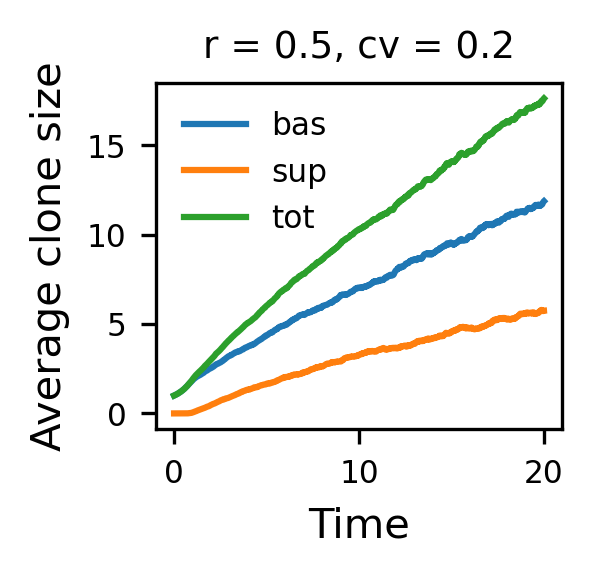

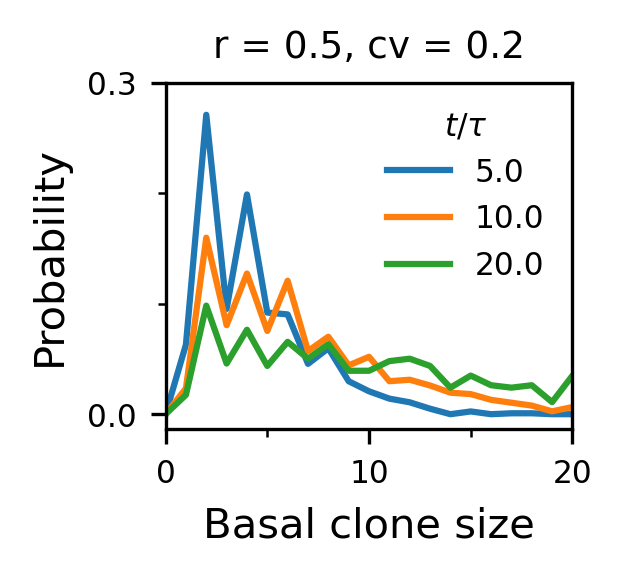

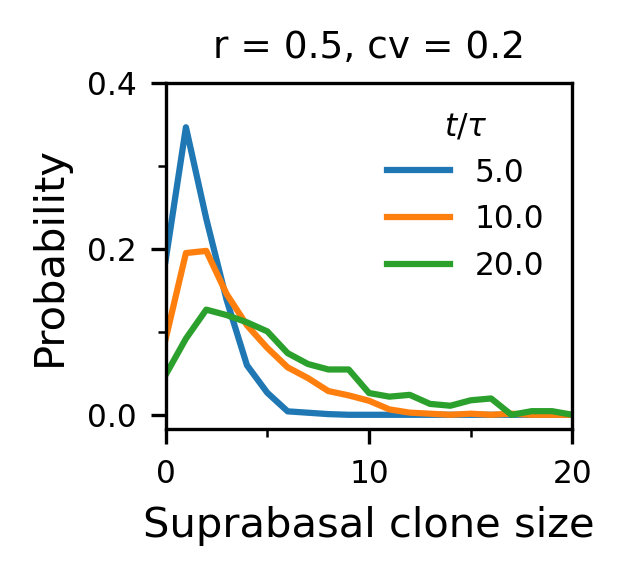

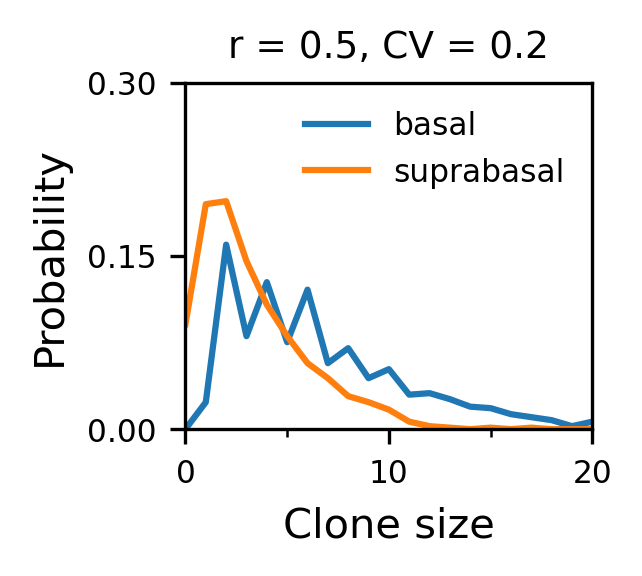

In [5]:
r = 0.5
cv = 0.2
rho = 0.5

plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.plot(time, ca_cv.av_bas_cs, label = 'bas')
plt.plot(time, ca_cv.av_sup_cs, label = 'sup')
plt.plot(time, ca_cv.av_tot_cs, label = 'tot')
plt.legend(frameon = False)    
plt.ylabel('Average clone size')
plt.xlabel('Time')
plt.title(rf'r = {r}, cv = {cv}')
plt.show()  


cpdf = ca_cv.bas_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.plot(cpdf[ctimes,:].transpose())
plt.legend(ctimes*skip/tau, title = r'$t/\tau$', frameon = False)
plt.xlabel('Basal clone size')
plt.ylabel('Probability')
plt.title(rf'r = {r}, cv = {cv}')
plt.xlim([0,20])
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
plt.yticks([0,0.1,0.2,0.3], minor = True)
plt.yticks([0,0.3])
plt.show()


cpdf = ca_cv.sup_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.plot(cpdf[ctimes,:].transpose())
plt.xlim([0,20])
plt.legend(ctimes*skip/tau, title = r'$t/\tau$', frameon = False)
plt.xlabel('Suprabasal clone size')
plt.ylabel('Probability')
plt.title(rf'r = {r}, cv = {cv}')
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.yticks([0,0.2,0.4])
plt.show()



bpdf = ca_cv.bas_pdf()
spdf = ca_cv.sup_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.plot(bpdf[ctimes[1],:].transpose(), label = 'basal')
plt.plot(spdf[ctimes[1],:].transpose(), label = 'suprabasal')
plt.legend(frameon = False)
plt.xlabel('Clone size')
plt.ylabel('Probability')
plt.title(rf'r = {r}, CV = {cv}')
plt.xlim([0,20])
plt.ylim([0,0.3])
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
#plt.yticks([0,0.1,0.3], minor = True)
plt.yticks([0,0.15,0.3])
plt.show()

In [5]:
''' 
    Bias to symmetric divisions with coordination between divisions
'''

tsteps = 10000
skip = 10
tau  = 500
shed = tau
ncells = 5000

r = 0.9
c = 1.0
rho = 0.5
sbas_cv = 0.1

t0 = sim_model.SD_0D(ncells, tau, rho = rho, r = r, p = 0.5, shed = shed, 
                     CVd_S = 1.0, CVd_D = 1.0, 
                     corrDD = c, corrSD = 0, corrSS = c,
                     sbas_cv = sbas_cv)

results = t0.simFull(tsteps = tsteps, skip = skip)
t0.reset()
results = t0.simFull(tsteps = tsteps, skip = skip)

time = np.arange(0, tsteps+1, skip)/tau
time0 = np.arange(0, tsteps+1)/tau


ca_sym = clones.sanalysis(results, popnames = ['D', 'S'], skip = skip, containsBasal=True)


Starting sim with 5000 cells at Tue Aug 19 16:53:38 2025
Ending sim with 5059 cells at Tue Aug 19 16:54:32 2025
Resetting time and division times
Starting sim with 5059 cells at Tue Aug 19 16:54:46 2025
Ending sim with 4902 cells at Tue Aug 19 16:56:23 2025


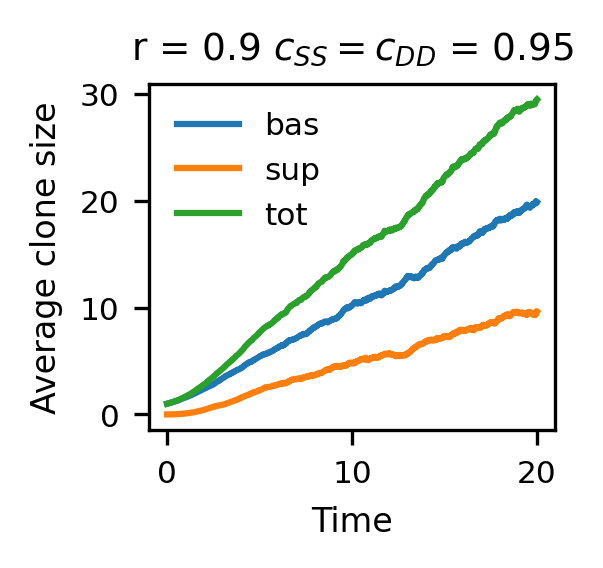

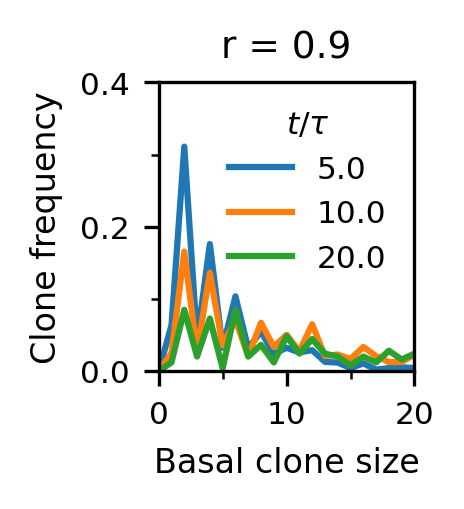

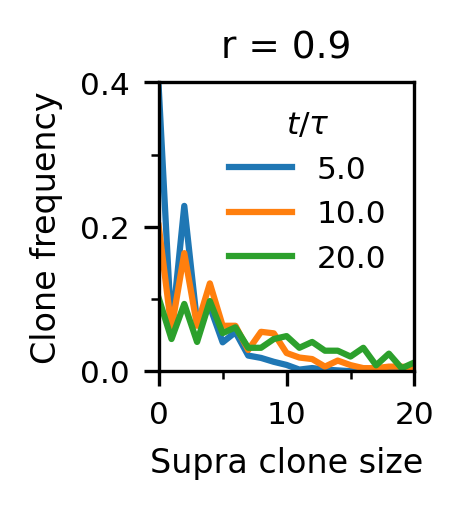

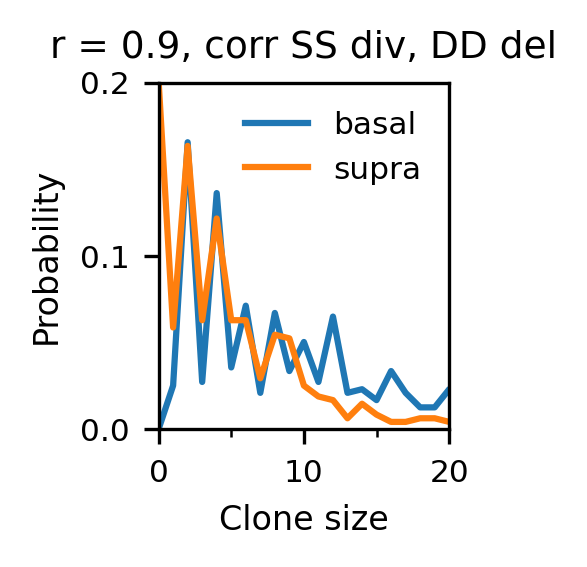

In [22]:
r = 0.9
c = 0.95
rho = 0.5
sbas_cv = 0.1

time = np.arange(0, tsteps+1, skip)/tau

plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.plot(time, ca_sym.av_bas_cs, label = 'bas')
plt.plot(time, ca_sym.av_sup_cs, label = 'sup')
plt.plot(time, ca_sym.av_tot_cs, label = 'tot')
plt.legend(frameon = False)    
plt.ylabel('Average clone size')
plt.xlabel('Time')
plt.title(f'r = {r} ' + r'$c_{SS} = c_{DD}$ = ' + f'{c}')
plt.show()  

cpdf = ca_sym.bas_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (1.1,1.25), dpi = 300)
plt.plot(cpdf[ctimes,:].transpose())
plt.xlim([0,20])
plt.legend(ctimes*skip/tau, title = r'$t/\tau$', frameon = False)
plt.xlabel('Basal clone size')
plt.ylabel('Clone frequency')
#plt.title(f'r = {r}' + r', $c_{SS} = c_{DD}$ = ' + f'{c}')
#plt.title(f'r = {r}, corr SS div, DD del')
plt.title(f'r = {r}')
plt.xlim([0,20])
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
#plt.yticks(np.linspace(0,0.5,6), minor = True)
plt.yticks([0,0.2,0.4])
plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.ylim([0,0.4])
plt.savefig(f'{savefolder}/baspdf_r0.9_.pdf', dpi = 300, bbox_inches = 'tight')
plt.show()


cpdf = ca_sym.sup_pdf()
ctimes =  np.array([250,500,1000])
#plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.figure(figsize = (1.1,1.25), dpi = 300)

plt.plot(cpdf[ctimes,:].transpose())
plt.xlim([0,12])
plt.legend(ctimes*skip/tau, title = r'$t/\tau$', frameon = False)
plt.xlabel('Supra clone size')
plt.ylabel('Clone frequency')
#plt.title(f'r = {r}' + r', $c_{SS} = c_{DD}$ = ' + f'{c}')
#plt.title(f'r = {r}, corr SS div, DD del')
plt.title(f'r = {r}')
plt.xlim([0,20])
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
#plt.yticks(np.linspace(0,0.5,6), minor = True)
plt.yticks([0,0.2,0.4])
plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.ylim([0,0.4])
plt.savefig(f'{savefolder}/suppdf_r0.9_.pdf', dpi = 300, bbox_inches = 'tight')
plt.show()

bpdf = ca_sym.bas_pdf()
spdf = ca_sym.sup_pdf()
ctimes =  np.array([250,500,1000])
#plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.figure(figsize = (1.25,1.5), dpi = 300)

#plt.plot(bpdf[ctimes[0],:].transpose(), label = f'bas: {ctimes[0]*skip/tau}')
plt.plot(bpdf[ctimes[1],:].transpose(), label = f'basal')
plt.plot(spdf[ctimes[1],:].transpose(), label = f'supra')
plt.xlim([0,20])
plt.ylim([0,0.2])
plt.legend(frameon = False)
plt.xlabel('Clone size')
plt.ylabel('Probability')

#plt.title(f'r = {r}' + r', $c_{SS} = c_{DD}$ = ' + f'{c}')
plt.title(f'r = {r}, corr SS div, DD del')
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
plt.yticks([0,0.1,0.2])
plt.show()

In [3]:
''' 
    Bias to asymmetric divisions with coordination between asymmetric divisions and delamination
'''

tsteps = 10000
skip = 10
tau  = 500
shed = tau
ncells = 5000

r = 0.1
c = 1.0
rho = 0.5
sbas_cv = 0.1

t0 = sim_model.SD_0D(ncells, tau, rho = rho, r = r, p = 0.5, shed = shed, 
                     CVd_S = 1.0, CVd_D = 1.0, 
                     corrDD = 0, corrSD = c, corrSS = 0,
                     sbas_cv = sbas_cv)

results = t0.simFull(tsteps = tsteps, skip = skip)
t0.reset()
results = t0.simFull(tsteps = tsteps, skip = skip)

time = np.arange(0, tsteps+1, skip)/tau
time0 = np.arange(0, tsteps+1)/tau


ca_ass = clones.sanalysis(results, popnames = ['S'], skip = skip, containsBasal=True)



Starting sim with 5000 cells at Tue Aug 19 16:50:26 2025
Ending sim with 5162 cells at Tue Aug 19 16:51:25 2025
Resetting time and division times
Starting sim with 5162 cells at Tue Aug 19 16:51:40 2025
Ending sim with 5195 cells at Tue Aug 19 16:53:31 2025


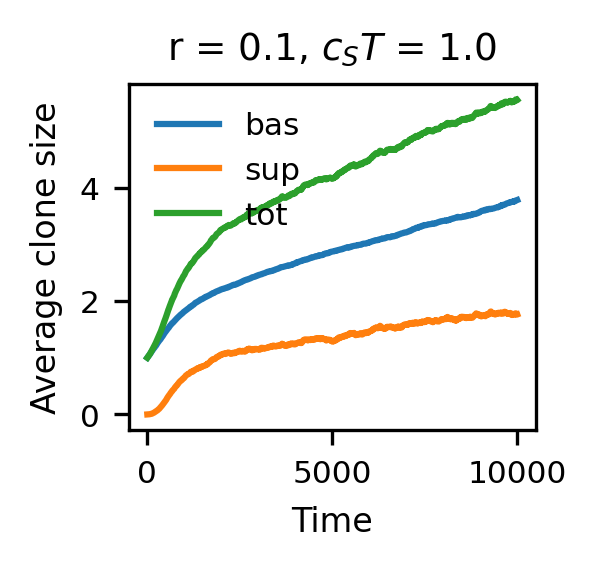

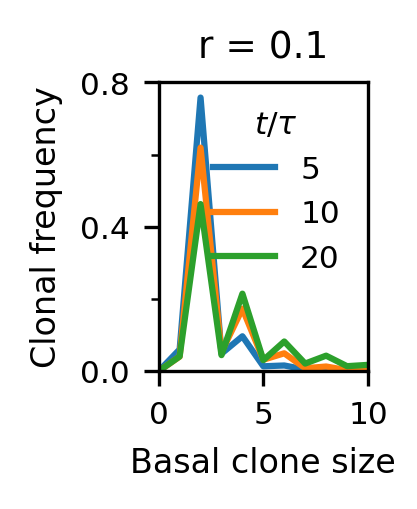

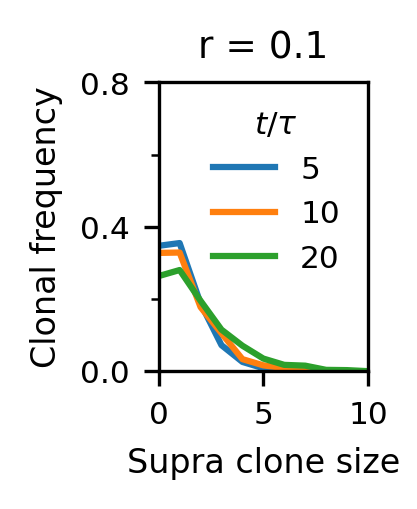

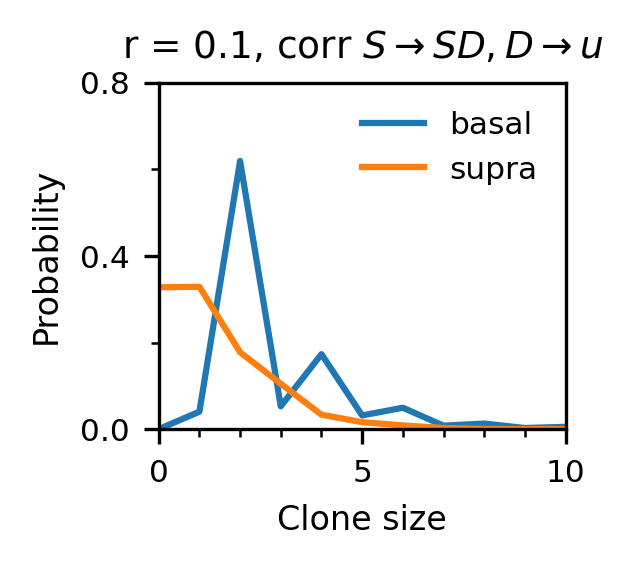

In [25]:
r = 0.1
c = 1.0
rho = 0.5
sbas_cv = 0.1
time = ca_ass.tvals

plt.figure(figsize = (1.75,1.5), dpi = 300)
plt.plot(time, ca_ass.av_bas_cs, label = 'bas')
plt.plot(time, ca_ass.av_sup_cs, label = 'sup')
plt.plot(time, ca_ass.av_tot_cs, label = 'tot')
plt.legend(frameon = False)    
plt.ylabel('Average clone size')
plt.xlabel('Time')
plt.title(rf'r = {r}, $c_ST$ = {c}')
plt.show()  

cpdf = ca_ass.bas_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (0.9,1.25), dpi = 300)
plt.plot(cpdf[ctimes,:].transpose())
plt.xlim([0,12])
plt.legend((ctimes*skip/tau).astype(int), title = r'$t/\tau$', frameon = False)
plt.xlabel('Basal clone size')
plt.ylabel('Clonal frequency')
plt.title(rf'r = {r}')
#plt.title(rf'r = {r}, $c_ST$ = {c}')
#plt.title(rf'r = {r}, corr $S\rightarrow SD, D\rightarrow u$')
plt.xticks([0,5,10])
plt.xlim([0,10])
#plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.yticks([0,0.4,0.8])
plt.yticks([0,0.2,0.4,0.6,0.8], minor = True)
plt.ylim([0,0.8])
plt.savefig(f'{savefolder}/baspdf_r0.1_.pdf', dpi = 300, bbox_inches = 'tight')
plt.show()


cpdf = ca_ass.sup_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (0.9,1.25), dpi = 300)
plt.plot(cpdf[ctimes,:].transpose())
plt.xlim([0,12])
plt.legend((ctimes*skip/tau).astype(int), title = r'$t/\tau$', frameon = False)
plt.xlabel('Supra clone size')
plt.ylabel('Clonal frequency')
plt.title(rf'r = {r}')
#plt.title(rf'r = {r}, $c_ST$ = {c}')
#plt.title(rf'r = {r}, corr $S\rightarrow SD, D\rightarrow u$')
plt.xticks([0,5,10])
plt.yticks([0,0.2,0.4,0.6,0.8], minor = True)
plt.xlim([0,10])
plt.yticks([0,0.4,0.8])
plt.ylim([0,0.8])
plt.savefig(f'{savefolder}/suppdf_r0.1_.pdf', dpi = 300, bbox_inches = 'tight')
plt.show()


bpdf = ca_ass.bas_pdf()
spdf = ca_ass.sup_pdf()
ctimes =  np.array([250,500,1000])
plt.figure(figsize = (1.75,1.5), dpi = 300)
#plt.plot(bpdf[ctimes[0],:].transpose(), label = f'bas: {ctimes[0]*skip/tau}')
plt.plot(bpdf[ctimes[1],:].transpose(), label = f'basal')
plt.plot(spdf[ctimes[1],:].transpose(), label = f'supra')
plt.xlim([0,10])
plt.ylim([0,0.8])
plt.legend(frameon = False)
plt.xlabel('Clone size')
plt.ylabel('Probability')
plt.title(rf'r = {r}, corr $S\rightarrow SD, D\rightarrow u$')
plt.xticks([0,5,10])
plt.xticks(np.arange(10), minor = True)
plt.yticks([0,0.4,0.8])
plt.yticks([0,0.2,0.4,0.6,0.8], minor = True)
plt.show()

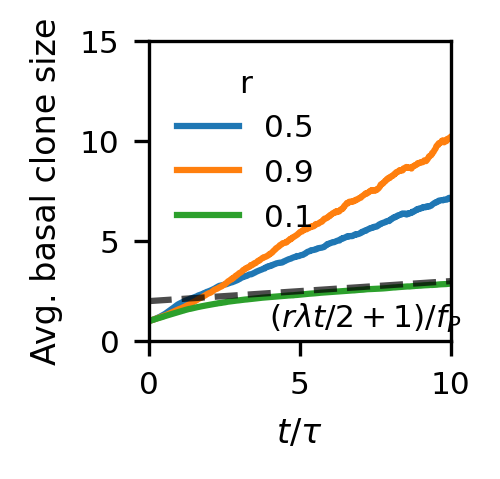

In [24]:
plt.figure(figsize = (1.3,1.3), dpi = 300)
plt.plot( ca_cv.tvals/500, ca_cv.av_bas_cs, label = r'0.5')
plt.plot(ca_sym.tvals/500, ca_sym.av_bas_cs, label = r'0.9')
plt.plot(ca_ass.tvals/500, ca_ass.av_bas_cs, label = r'0.1')
plt.plot(ca_ass.tvals/500, ((ca_ass.tvals/500)*0.1/2 + 1)*2, 'k--', alpha = 0.7)
plt.text(4.0,0.7,r'$(r\lambda t/2 + 1)/f_P$')
plt.legend(title = 'r', frameon = False)
plt.xlabel(r'$t/\tau$')
plt.ylabel('Avg. basal clone size')
plt.ylim([0,15])
plt.xlim([0,10])
plt.xticks([0,5,10])
plt.yticks([0,5,10,15])
#plt.xticks(np.arange(11), minor = True)
#plt.yticks(np.arange(16), minor = True)
plt.savefig(f'{savefolder}/_av_size_P3.pdf', dpi = 300, bbox_inches = 'tight')
plt.show()